<a href="https://colab.research.google.com/github/814725243064-jxc/SmartBank---Integrated-Banking-Management-Customer-Churn-System/blob/main/EDA%20MINOR%20PROJECT%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Recreate the cleaned dataset (clean_df) exactly as in the mini project notebook
np.random.seed(42)
n_samples = 10000

data = {
    'CustomerID': range(15600000, 15610000),
    'CreditScore': np.random.randint(350, 850, size=n_samples),
    'Geography': np.random.choice(['France', 'Spain', 'Germany'], size=n_samples, p=[0.5, 0.25, 0.25]),
    'Gender': np.random.choice(['Male', 'Female'], size=n_samples, p=[0.52, 0.48]),
    'Age': np.random.randint(18, 75, size=n_samples),
    'Tenure': np.random.randint(0, 10, size=n_samples),
    'Balance': np.random.uniform(0, 250000, size=n_samples),
    'NumOfProducts': np.random.choice([1, 2, 3, 4], size=n_samples, p=[0.5, 0.4, 0.08, 0.02]),
    'HasCrCard': np.random.choice([0, 1], size=n_samples, p=[0.3, 0.7]),
    'IsActiveMember': np.random.choice([0, 1], size=n_samples, p=[0.48, 0.52]),
    'EstimatedSalary': np.random.uniform(10000, 200000, size=n_samples),
    'Exited': np.random.choice([0, 1], size=n_samples, p=[0.8, 0.2])
}
raw_df = pd.DataFrame(data)
clean_df = raw_df.drop_duplicates().dropna()

# Save the cleaned data as a CSV file and use it as the model input
clean_df.to_csv("cleaned_bank_churn_data.csv", index=False)
df = pd.read_csv("cleaned_bank_churn_data.csv")

# Clean column names
df.columns = df.columns.astype(str).str.strip()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 110)
print("\nDataset loaded successfully!")
print("\nFirst 5 records:")
print(df.head())
print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset loaded successfully!

First 5 records:
   CustomerID  CreditScore Geography  Gender  Age  Tenure        Balance  NumOfProducts  HasCrCard  \
0    15600000          452    France  Female   61       1  113528.171589              1          0   
1    15600001          785    France    Male   70       6  138786.963707              2          0   
2    15600002          698    France  Female   67       2  233169.998092              1          0   
3    15600003          620     Spain  Female   67       4  132888.460413              1          1   
4    15600004          456    France    Male   21       6   76306.622470              2          1   

   IsActiveMember  EstimatedSalary  Exited  
0               0    196497.367656       1  
1               0    103499.548919       0  
2               1    111821.652267       0  
3               0    126314.621842       0  
4               0    193244.231234       0  

Dataset Shape: (10000, 12)

Column Names: ['CustomerID', 'CreditScor

In [4]:
target = "Exited"
features = [
    "CreditScore", "Geography", "Gender", "Age", "Tenure",
    "Balance", "NumOfProducts", "HasCrCard",
    "IsActiveMember", "EstimatedSalary"
]
required = features + [target]
missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

df = df.dropna(subset=[target]).copy()

# CustomerID is only an identifier, so it is not used as a feature
# Encode categorical variables (Gender -> 0/1, Geography -> one-hot columns)
df["Gender"] = df["Gender"].map({"Female": 0, "Male": 1})
df = pd.get_dummies(df, columns=["Geography"], dtype=int)

# Convert feature columns to numeric
features = [c for c in df.columns if c not in ["CustomerID", target]]
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows where all feature values are missing
df = df.dropna(subset=features, how="all")
X = df[features]
y = df[target]

print("Prepared Dataset Shape:", df.shape)
print("\nInput Features:", features)
print("\nChurn Category Counts:")
print(y.value_counts())
if y.nunique() < 2:
    raise ValueError(
        "At least two Exited categories are needed for classification."
    )

Prepared Dataset Shape: (10000, 14)

Input Features: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_France', 'Geography_Germany', 'Geography_Spain']

Churn Category Counts:
Exited
0    8022
1    1978
Name: count, dtype: int64


In [5]:
class_counts = y.value_counts()
number_of_classes = y.nunique()

# Ensure the test set can hold at least one record per class
test_records = max(
    int(np.ceil(0.20 * len(y))),
    number_of_classes
)

# Ensure enough records remain for training
if test_records >= len(y):
    raise ValueError(
        "Dataset is too small for a train-test split. "
        "Add more records to the dataset."
    )
stratify_y = (
    y if class_counts.min() >= 2 else None
)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=test_records,
    random_state=42,
    stratify=stratify_y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training categories:", y_train.nunique())
print("Testing categories:", y_test.nunique())

Training records: 8000
Testing records: 2000
Training categories: 2
Testing categories: 2


In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000, class_weight="balanced"
        ))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=3,
            random_state=42,
            class_weight="balanced"
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=3,
            random_state=42,
            class_weight="balanced"
        ))
    ])
}
print("Models created:", list(models.keys()))

Models created: ['Logistic Regression', 'Decision Tree', 'Random Forest']


Logistic Regression
Accuracy: 0.499
Precision: 0.5008
Recall: 0.5013
F1 Score: 0.4498

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.50      0.61      1604
           1       0.20      0.51      0.29       396

    accuracy                           0.50      2000
   macro avg       0.50      0.50      0.45      2000
weighted avg       0.68      0.50      0.55      2000



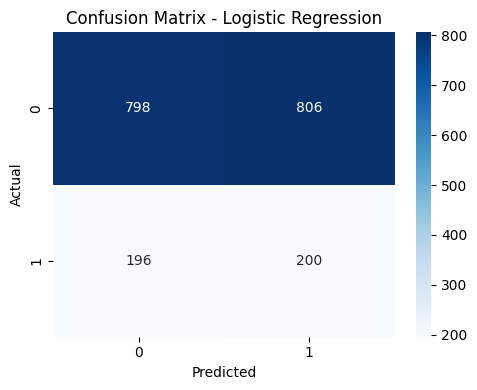

In [7]:
results = []
trained_models = {}

def evaluate(name, model):
    print(name)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[name] = model
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions,
        average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, predictions,
        average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, predictions,
        average="macro", zero_division=0
    )
    results.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4)
    })
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))
    # Confusion Matrix
    cm = confusion_matrix(
        y_test, predictions, labels=np.unique(y)
    )
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

evaluate("Logistic Regression", models["Logistic Regression"])

Decision Tree
Accuracy: 0.3685
Precision: 0.4976
Recall: 0.4969
F1 Score: 0.3636

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.28      0.42      1604
           1       0.20      0.71      0.31       396

    accuracy                           0.37      2000
   macro avg       0.50      0.50      0.36      2000
weighted avg       0.68      0.37      0.40      2000



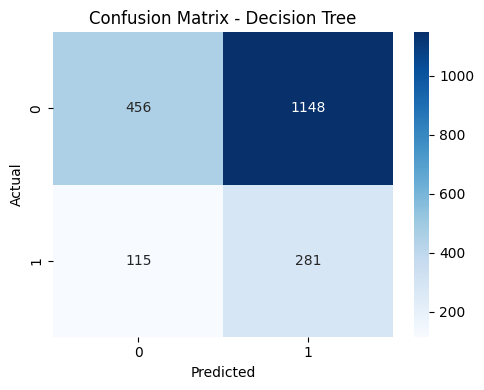

In [8]:
evaluate("Decision Tree", models["Decision Tree"])

Random Forest
Accuracy: 0.536
Precision: 0.4973
Recall: 0.4958
F1 Score: 0.4642

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.56      0.66      1604
           1       0.19      0.43      0.27       396

    accuracy                           0.54      2000
   macro avg       0.50      0.50      0.46      2000
weighted avg       0.68      0.54      0.58      2000



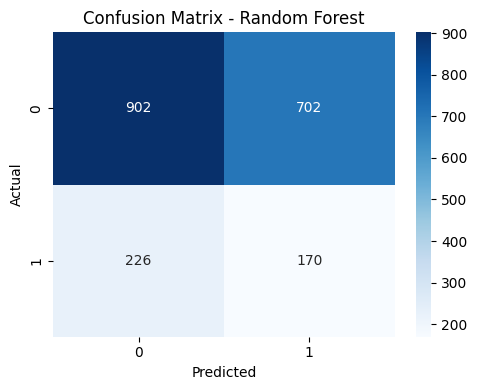

In [9]:
evaluate("Random Forest", models["Random Forest"])

In [14]:
comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    by="F1 Score", ascending=False
)
print("MODEL COMPARISON")
print(comparison.to_string(index=False))

best_model_name = comparison.iloc[0]["Model"]
print("\nBest model on this test split:", best_model_name)
print("Based on macro F1 score.")
print("This is a preliminary result; the dataset is simulated.")

MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score
      Random Forest    0.5360     0.4973  0.4958    0.4642
Logistic Regression    0.4990     0.5008  0.5013    0.4498
      Decision Tree    0.3685     0.4976  0.4969    0.3636

Best model on this test split: Random Forest
Based on macro F1 score.
This is a preliminary result; the dataset is simulated.


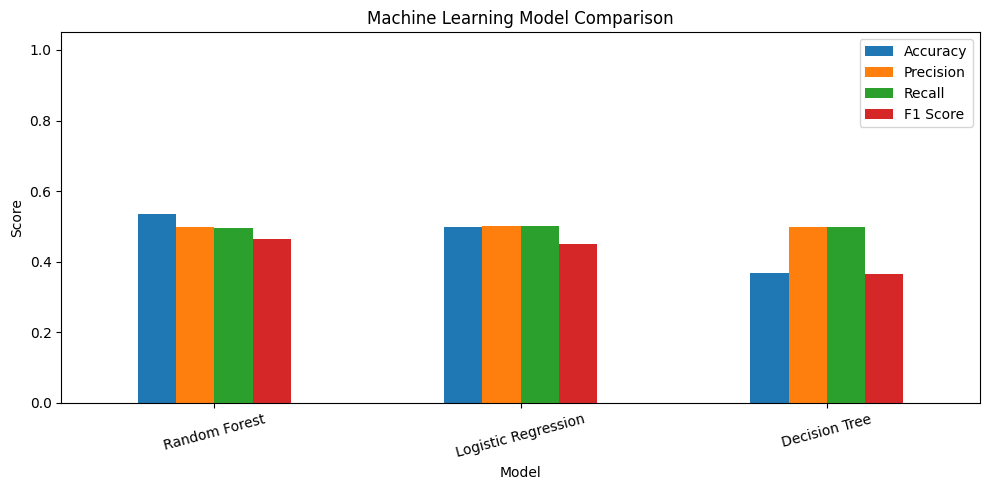

In [15]:
comparison.plot(
    x="Model",
    y=["Accuracy", "Precision", "Recall", "F1 Score"],
    kind="bar",
    figsize=(10, 5)
)
plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Feature Importance - Decision Tree
EstimatedSalary      0.683429
Tenure               0.115562
IsActiveMember       0.108276
CreditScore          0.092733
Age                  0.000000
Gender               0.000000
NumOfProducts        0.000000
Balance              0.000000
HasCrCard            0.000000
Geography_France     0.000000
Geography_Germany    0.000000
Geography_Spain      0.000000
dtype: float64


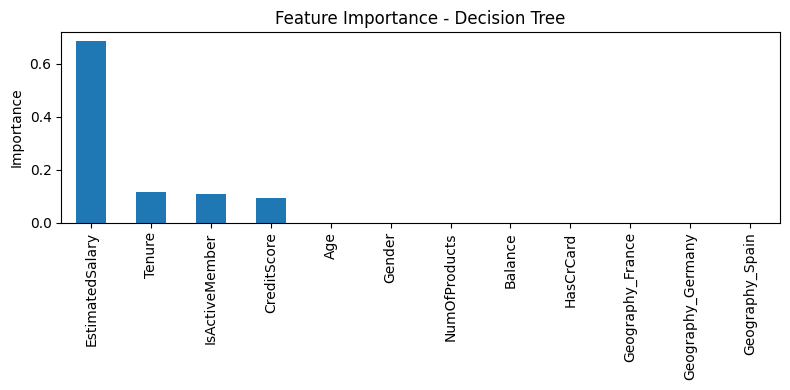


Feature Importance - Random Forest
EstimatedSalary      0.243347
Balance              0.225369
CreditScore          0.176994
Age                  0.112819
Tenure               0.097735
Geography_Germany    0.037561
NumOfProducts        0.030248
Geography_France     0.022802
HasCrCard            0.015466
Geography_Spain      0.013905
Gender               0.013643
IsActiveMember       0.010111
dtype: float64


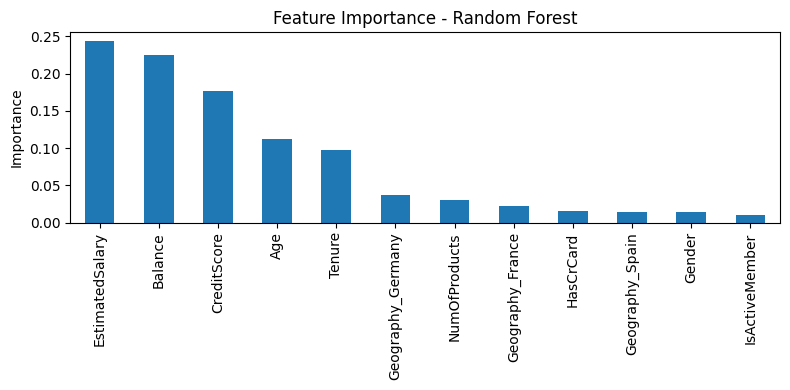

In [12]:
for name in ["Decision Tree", "Random Forest"]:
    fitted_pipeline = trained_models[name]
    classifier = fitted_pipeline.named_steps["model"]
    importance = pd.Series(
        classifier.feature_importances_,
        index=features
    ).sort_values(ascending=False)

    print(f"\nFeature Importance - {name}")
    print(importance)

    importance.plot(
        kind="bar",
        figsize=(8, 4),
        title=f"Feature Importance - {name}"
    )
    plt.ylabel("Importance")
    plt.tight_layout()
    plt.show()

In [13]:
print("\nPROJECT COMPLETED")
print("Dataset records used:", len(df))
print("Input features:", features)
print("Target variable:", target)
print("Models trained:", len(trained_models))
print("\nFinal Comparison:")
print(comparison.to_string(index=False))
print(
    "\nNOTE: The dataset is simulated with random values. "
    "The metrics must not be used for real banking decisions."
)


PROJECT COMPLETED
Dataset records used: 10000
Input features: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_France', 'Geography_Germany', 'Geography_Spain']
Target variable: Exited
Models trained: 3

Final Comparison:
              Model  Accuracy  Precision  Recall  F1 Score
      Random Forest    0.5360     0.4973  0.4958    0.4642
Logistic Regression    0.4990     0.5008  0.5013    0.4498
      Decision Tree    0.3685     0.4976  0.4969    0.3636

NOTE: The dataset is simulated with random values. The metrics must not be used for real banking decisions.
